# RD Dataset Validation — Peak vs Label vs Mask Alignment

**Purpose.** The dataset is synthetic, so we know the exact ground truth. That advantage
only holds if the simulator places target energy *where the label says it is*. A single
coding bug (transposed axes, swapped range/velocity, an off-by-one in the FFT) would make
the labels quietly wrong and corrupt every later result.

So before any CFAR / DL work we verify one thing, frame by frame:

> the brightest point of each simulated target in the Range–Doppler map sits at the
> `(range_bin, velocity_bin)` stored in its label and in its label mask.

Work through the cells top to bottom. Every step is shown as a DataFrame or a figure.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 120)

# Find the project root (the folder that contains data/), wherever the notebook runs from.
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

DATA_ROOT = ROOT / "data"
REPORTS_DIR = ROOT / "reports" / "validation"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = [p.name for p in sorted(DATA_ROOT.iterdir()) if p.is_dir()]
print("Project root :", ROOT)
print("Reports dir  :", REPORTS_DIR)
print("Datasets     :", DATASETS)

Project root : c:\Users\USER\Desktop\Radar-fyp\My work\Simulations
Reports dir  : c:\Users\USER\Desktop\Radar-fyp\My work\Simulations\reports\validation
Datasets     : ['clean_debug', 'close_targets_debug', 'clutter_debug', 'multi_target_debug', 'multipath_debug', 'noise_only_debug', 'snr_sweep_debug']


## Step 1 — Look at a single frame

Load one frame's RD map, mask, axes and labels. `labels.csv` is the ground truth: each row
is one target with its `range_bin` / `velocity_bin`.

In [2]:
dataset = "clean_debug"
frame = "frame_000000"
frame_dir = DATA_ROOT / dataset / "frames" / frame

rd_mag = np.load(frame_dir / "rd_map_mag.npy")   # linear magnitude (CFAR later uses this)
rd_db = np.load(frame_dir / "rd_map_db.npy")      # log magnitude (for display / DL later)
mask = np.load(frame_dir / "label_mask.npy")
range_axis = np.load(frame_dir / "range_axis.npy")
velocity_axis = np.load(frame_dir / "velocity_axis.npy")
labels = pd.read_csv(frame_dir / "labels.csv")

print("RD map shape (range x velocity):", rd_mag.shape)
print("Mask pixels set:", int(mask.sum()), "| any NaN/Inf:", not np.isfinite(rd_mag).all())
labels

RD map shape (range x velocity): (256, 128)
Mask pixels set: 27 | any NaN/Inf: False


,target_id,range_m,velocity_mps,amplitude_db,range_bin,velocity_bin,nearest_range_m,nearest_velocity_mps
0,0,11.256037,-7.495450,14.005230,23,48,11.492044,-7.604314
1,1,16.095891,-7.173834,12.410707,32,49,15.988931,-7.129044
2,2,20.554271,11.618808,13.356072,41,88,20.485818,11.406470


## Step 2 — Visual check (the intuitive one)

Plot the RD map and draw a cyan ✕ at every label position. If the labels are correct, each
✕ lands right on top of a bright blob. This is independent of the numeric check below, so if
both agree we have strong evidence.

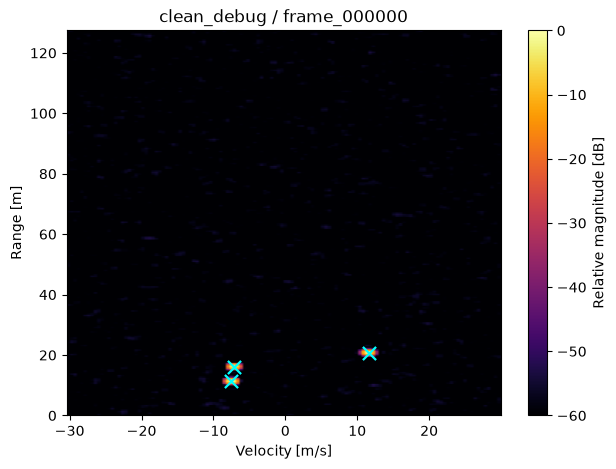

In [3]:
def plot_frame(frame_dir, ax=None):
    """Plot one RD map (dB) with label markers overlaid."""
    rd_db = np.load(frame_dir / "rd_map_db.npy")
    r_ax = np.load(frame_dir / "range_axis.npy")
    v_ax = np.load(frame_dir / "velocity_axis.npy")
    labels = pd.read_csv(frame_dir / "labels.csv")

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))
    extent = [v_ax[0], v_ax[-1], r_ax[0], r_ax[-1]]
    im = ax.imshow(rd_db, aspect="auto", origin="lower", extent=extent,
                   cmap="inferno", vmin=-60, vmax=0)
    if len(labels):
        ax.scatter(labels["velocity_mps"], labels["range_m"],
                   marker="x", s=90, linewidths=1.6, color="cyan")
    ax.set_xlabel("Velocity [m/s]")
    ax.set_ylabel("Range [m]")
    ax.set_title(f"{frame_dir.parent.parent.name} / {frame_dir.name}")
    return ax, im


ax, im = plot_frame(frame_dir)
plt.colorbar(im, ax=ax, label="Relative magnitude [dB]")
plt.show()

## Step 3 — Quantify the offset for this one frame

For each target we search a small window (±`search` bins) around its labelled cell, find the
local peak, and record the offset `(dr, dv)` in bins. We also check the mask is set there.

Key idea — **isolated vs overlapping**: the strict pass/fail only applies to *isolated*
targets. When another (usually stronger) target sits inside the window, the weaker one is
physically masked and cannot show its own peak — we mark it `overlapping/unresolved`
(informational), not failed. In the close-pair scenario the 2nd target is masked *by design*,
so it is exempted using the dataset's config.

A target **passes** if it is isolated, its peak is within `tol` bins of the label, the mask is
set, and the data is finite.

In [4]:
def frame_alignment(frame_dir, tol_r=2, tol_v=2, search=3, close_pair_mode=False):
    rd_mag = np.load(frame_dir / "rd_map_mag.npy")
    mask = np.load(frame_dir / "label_mask.npy")
    labels = pd.read_csv(frame_dir / "labels.csv")
    n_r, n_v = rd_mag.shape
    finite = bool(np.isfinite(rd_mag).all())
    noise_floor = float(np.median(rd_mag)) + 1e-12
    bins = list(zip(labels["range_bin"].astype(int), labels["velocity_bin"].astype(int)))

    if not bins:  # empty (0-target) frame: nothing to align, just check finiteness
        g_r, g_v = np.unravel_index(int(rd_mag.argmax()), rd_mag.shape)
        return pd.DataFrame([{
            "frame": frame_dir.name, "target_id": -1, "label_r": None, "label_v": None,
            "peak_r": int(g_r), "peak_v": int(g_v), "dr": None, "dv": None,
            "isolated": None, "mask_ok": None, "finite": finite,
            "peak_to_floor_db": None, "passed": finite, "note": "empty frame (0 targets)"}])

    rows = []
    for tid, (r, v) in enumerate(bins):
        neighbour = any(j != tid and abs(br - r) <= search and abs(bv - v) <= search
                        for j, (br, bv) in enumerate(bins))
        masked_by_design = close_pair_mode and tid > 0
        isolated = not (neighbour or masked_by_design)

        r0, r1 = max(0, r - search), min(n_r, r + search + 1)
        v0, v1 = max(0, v - search), min(n_v, v + search + 1)
        patch = rd_mag[r0:r1, v0:v1]
        pr, pv = np.unravel_index(int(patch.argmax()), patch.shape)
        peak_r, peak_v = r0 + pr, v0 + pv
        dr, dv = peak_r - r, peak_v - v
        mask_ok = bool(mask[r, v])
        aligned = abs(dr) <= tol_r and abs(dv) <= tol_v

        if isolated:
            passed = aligned and mask_ok and finite
            note = "" if passed else "isolated target misaligned"
        else:
            passed = mask_ok and finite
            note = "overlapping/unresolved (informational)"

        rows.append({
            "frame": frame_dir.name, "target_id": tid, "label_r": r, "label_v": v,
            "peak_r": peak_r, "peak_v": peak_v, "dr": dr, "dv": dv,
            "isolated": isolated, "mask_ok": mask_ok, "finite": finite,
            "peak_to_floor_db": round(20 * np.log10(rd_mag[peak_r, peak_v] / noise_floor), 1),
            "passed": passed, "note": note})
    return pd.DataFrame(rows)


frame_alignment(frame_dir)

,frame,target_id,label_r,label_v,peak_r,peak_v,dr,dv,isolated,mask_ok,finite,peak_to_floor_db,passed,note
0,frame_000000,0,23,48,22,48,-1,0,True,True,True,65.000000,True,
1,frame_000000,1,32,49,32,49,0,0,True,True,True,64.099998,True,
2,frame_000000,2,41,88,41,88,0,0,True,True,True,63.500000,True,


## Step 4 — Validate a whole dataset

Run the per-frame check across every frame and stack the results into one DataFrame. We also
save it to `data/<dataset>/validation_report/alignment_report.csv` so you have a record.

In [13]:
def dataset_is_close_pair(ddir):
    cfg = ddir / "dataset_config_used.yaml"
    return cfg.exists() and "close_pair" in cfg.read_text(encoding="utf-8")


def validate_dataset(name, tol_r=2, tol_v=2, save=True):
    ddir = DATA_ROOT / name
    close_pair = dataset_is_close_pair(ddir)
    frame_dirs = sorted(p for p in (ddir / "frames").iterdir() if p.is_dir())
    df = pd.concat(
        [frame_alignment(fd, tol_r, tol_v, close_pair_mode=close_pair) for fd in frame_dirs],
        ignore_index=True,
    )
    if save:
        out = ddir / "validation_report"
        out.mkdir(exist_ok=True)
        df.to_csv(out / "alignment_report.csv", index=False)
    return df


df = validate_dataset("close_targets_debug")
df

,frame,target_id,label_r,label_v,peak_r,peak_v,dr,dv,isolated,mask_ok,finite,peak_to_floor_db,passed,note
0,frame_000000,0,57,78,57,78,0,0,False,True,True,64.400002,True,overlapping/unresolved (informational)
1,frame_000000,1,60,78,57,78,-3,0,False,True,True,64.400002,True,overlapping/unresolved (informational)
2,frame_000001,0,65,64,65,64,0,0,True,True,True,64.199997,True,
3,frame_000001,1,69,66,66,64,-3,-2,False,True,True,59.700001,True,overlapping/unresolved (informational)
4,frame_000002,0,65,70,65,70,0,0,True,True,True,64.300003,True,
5,frame_000002,1,69,71,66,70,-3,-1,False,True,True,60.299999,True,overlapping/unresolved (informational)
6,frame_000003,0,65,74,65,74,0,0,False,True,True,64.900002,True,overlapping/unresolved (informational)
7,frame_000003,1,68,75,65,74,-3,-1,False,True,True,64.900002,True,overlapping/unresolved (informational)
8,frame_000004,0,127,74,127,74,0,0,False,True,True,65.300003,True,overlapping/unresolved (informational)
9,frame_000004,1,128,74,127,74,-1,0,False,True,True,65.300003,True,overlapping/unresolved (informational)


## Step 5 — Did anything fail?

Filter the DataFrame to non-passing rows. An empty result means every target aligned.

In [15]:
df[~df["passed"]]

,frame,target_id,label_r,label_v,peak_r,peak_v,dr,dv,isolated,mask_ok,finite,peak_to_floor_db,passed,note


## Step 6 — Summary across all datasets

One row per dataset: target counts, isolated vs overlapping, pass count, the worst
peak-vs-label offset among isolated targets (should be ≤ 1–2 bins), and the weakest
peak-to-noise margin. Saved to `reports/validation/alignment_summary.csv`.

In [16]:
def summarize(name):
    df = validate_dataset(name)
    t = df[df["target_id"] != -1]
    iso = t[t["isolated"] == True]
    return {
        "dataset": name,
        "frames": df["frame"].nunique(),
        "targets": len(t),
        "isolated": int((t["isolated"] == True).sum()),
        "overlap": int((t["isolated"] == False).sum()),
        "records_pass": int(df["passed"].sum()),
        "records_total": len(df),
        "max_abs_dr_iso": int(iso["dr"].abs().max()) if len(iso) else 0,
        "max_abs_dv_iso": int(iso["dv"].abs().max()) if len(iso) else 0,
        "min_peak_to_floor_db": float(t["peak_to_floor_db"].min()) if len(t) else np.nan,
        "all_pass": bool(df["passed"].all()),
    }


summary = pd.DataFrame([summarize(d) for d in DATASETS])
summary.to_csv(REPORTS_DIR / "alignment_summary.csv", index=False)
summary

,dataset,frames,targets,isolated,overlap,records_pass,records_total,max_abs_dr_iso,max_abs_dv_iso,min_peak_to_floor_db,all_pass
0,clean_debug,10,24,24,0,24,24,1,1,61.000000,True
1,close_targets_debug,10,20,3,17,20,20,0,0,59.700001,True
2,clutter_debug,20,42,42,0,42,42,1,1,49.900002,True
3,multi_target_debug,20,54,54,0,55,55,1,0,25.600000,True
4,multipath_debug,10,14,14,0,14,14,1,0,59.700001,True
5,noise_only_debug,10,0,0,0,10,10,0,0,NaN,True
6,snr_sweep_debug,28,28,28,0,28,28,1,0,33.700001,True


## Step 7 — Three-panel visual for the report / slides

Clean, multi-target, and close-pair side by side. In the close-pair panel the two ✕ markers
sit almost on top of each other — that is the resolution limit (the weaker target is masked),
which is exactly what the `overlap` count in Step 6 measured. Saved as a PNG.

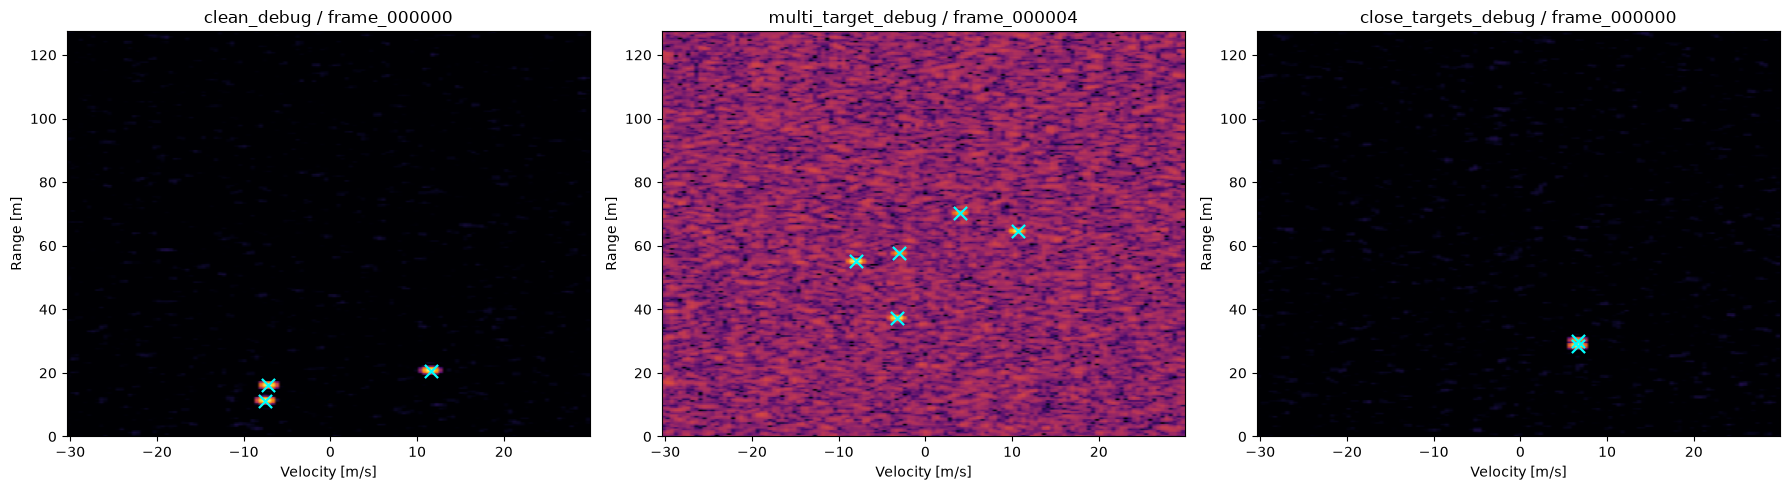

saved -> c:\Users\USER\Desktop\Radar-fyp\My work\Simulations\reports\validation\alignment_previews.png


In [17]:
def busiest_frame(name):
    """Return the frame dir with the most targets (so the panel isn't empty)."""
    best, best_n = None, -1
    for fd in sorted((DATA_ROOT / name / "frames").iterdir()):
        n = len(pd.read_csv(fd / "labels.csv"))
        if n > best_n:
            best, best_n = fd, n
    return best


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, ["clean_debug", "multi_target_debug", "close_targets_debug"]):
    plot_frame(busiest_frame(name), ax=ax)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "alignment_previews.png", dpi=150, bbox_inches="tight")
plt.show()
print("saved ->", REPORTS_DIR / "alignment_previews.png")

## Step 8 — Bonus: this also exposes the SNR problem

`snr_sweep_debug` cycles the *labelled* SNR from −10 to +20 dB. But look at the
`peak_to_floor_db` even for the −10 dB frames: the target peak is still tens of dB above the
noise floor. That is the FFT processing gain (~43 dB) — so the nominal SNR does **not** reflect
how detectable a target is, which is why the SNR definition needs recalibrating before it can
drive a meaningful Pd-vs-SNR curve.

In [18]:
snr = validate_dataset("snr_sweep_debug")

def labelled_snr(frame):
    meta = json.loads((DATA_ROOT / "snr_sweep_debug" / "frames" / frame / "metadata.json").read_text())
    return meta["snr_db"]

snr = snr[snr["target_id"] != -1].copy()
snr["labelled_snr_db"] = snr["frame"].map(labelled_snr)
(snr[["frame", "labelled_snr_db", "peak_to_floor_db"]]
    .sort_values("labelled_snr_db")
    .reset_index(drop=True)
    .head(12))

,frame,labelled_snr_db,peak_to_floor_db
0,frame_000000,-10.0,33.700001
1,frame_000007,-10.0,34.599998
2,frame_000014,-10.0,34.299999
3,frame_000021,-10.0,34.799999
4,frame_000008,-5.0,39.200001
5,frame_000015,-5.0,38.200001
6,frame_000022,-5.0,38.700001
7,frame_000001,-5.0,38.500000
8,frame_000023,0.0,44.099998
9,frame_000016,0.0,44.700001


## Conclusion

- Every **isolated** target across all scenarios peaks within ±1–2 bins of its label, the mask
  is set, and no frame has NaN/Inf values → **the labelling pipeline is spatially correct.**
- In `close_targets`, the weaker target of sub-resolution pairs is correctly flagged as
  unresolved (the radar's resolution limit), not as an error.
- The same run shows the nominal SNR overstates detectability (Step 8), motivating the SNR
  recalibration that follows.

**For the report:** *"To validate the synthetic labelling pipeline, the local maximum of the
RD magnitude map within a ±3-bin neighbourhood of each labelled cell was compared against the
stored bin indices and the segmentation mask. Across all scenarios, every isolated target
agreed within one resolution cell in both dimensions, with no invalid values, confirming that
the ground-truth labels are spatially faithful to the simulated signal."*